# Get a dataset of sentences containing the target term from articles
- **Author:** Naomi Baes

## Load Input Data and Examine its Structure

Note: Change to your input file of choice.

In [1]:
import os
import pandas as pd

# Set corpus to the folder of files you want to use
df_corpus = pd.read_csv('../input/ADHD_US_newsstream.tsv', sep='\t')
#df_corpus_test = pd.read_csv('../input/ADHD_US_newsstream_SAMPLE_1000.tsv', sep='\t')

# print descriptive information
print("Loaded:", df_corpus.shape, "news articles.")
df_corpus.head()
#df_corpus_test.head()


Loaded: (63963, 8) news articles.


,id,title,text,date,publisher,source_type,pub_province,year
0,306897379,Improving the Lot of the Learning Disabled,A couple with a learning-disabled son came to ...,1987-02-03,WP Company LLC d/b/a The Washington Post,Newspapers,DC,1987
1,389443159,"SCHOOL SWITCHES CAMPUS, NOT APPROACH",SCHOOLS WEST BROWARD When he was enrolled a...,1987-11-17,"Tribune Publishing Company, LLC",Newspapers,IL,1987
2,292639858,Troiani Case Co-Defendant Pleads Guilty to Murder,In a plea bargain that saved him from possible...,1987-11-05,Los Angeles Times Communications LLC,Newspapers,CA,1987
3,292482107,Paying Close Attention to Hyperactive Adults N...,A man walks down the street He says why a...,1987-04-14,Los Angeles Times Communications LLC,Newspapers,CA,1987
4,280637107,Foster Parents Learn About Infant Addicts,"Merry Lloyd looked down at Rusty, the tiny fos...",1988-12-11,Los Angeles Times Communications LLC,Newspapers,CA,1988


In [4]:
#!pip install spacy
#!pip install ipywidgets
#!jupyter nbextension enable --py widgetsnbextension

## Preprocessing Data

This script processes sentences containing target term in `text` column of the corpus to:
1) Normalize all variants of “ADHD” (including dotted forms and long-form names) to the single token ADHD
2) Remove any parenthetical (ADHD) that immediately follows them (replacing it with a single space)

Variants of ADHD: 
•	A.D.H.D.
•	Attention Deficit Hyperactivity Disorder
•	Attention-Deficit Hyperactivity Disorder
•	Attention-Deficit/Hyperactivity Disorder
•	Attention Deficit/Hyperactivity Disorder
•	A.D.D.
•	Attention Deficit Disorder
•	Attention-Deficit Disorder 


In [12]:
%run 0_step2_transform_variants_to_unigram.py


✅ Found changes. Showing up to 5 examples:

Example 1:
 Before: Q. I bought some Kern's Apricot Nectar in a bottle but did not realize until I got it home that six ounces contained 110 calories. This is high when one is trying to lose weight. How many teaspoons of sugar do six ounces contain? Why is so much sugar added to apricot drinks? The fruit itself is sweet enough, I would think.   - H. Campbell   Cotati, Calif.   A. If you put some apricots in a blender to make yourself a drink, what you would get is not juice but rather pureed apricots. The same would happen with peaches and pears. In the trade these pureed fruits are called nectars, which are the pulpy liquid from fruits. If you took your homemade apricot puree and diluted it with water to make it more liquid, it wouldn't be sweet enough. Some corn syrup and/or sugar would make it much more palatable.   I asked Nestle how much sugar is in their product, but they responded that such information was proprietary. I do know that 


Summary:
✓ Loaded 63,963 rows from /home/ec2-user/SageMaker/ADHD_conceptual_change/input/ADHD_US_newsstream.tsv
✓ Total ADHD-variant occurrences replaced: 115245
✓ Total parentheticals removed: 6935
✓ Remaining parentheticals after cleanup: 1280
✓ Cleaned text written to /home/ec2-user/SageMaker/ADHD_conceptual_change/input/ADHD_US_newsstream_normalized-ADHD.tsv


This script processes TSV files containing full-text news articles by:
1. Loading a transformer-based SpaCy language model (en_core_web_sm) to detect sentence boundaries (no lemmatization is applied): https://spacy.io/models/en
2. Extracting the target term automatically from the input filename (e.g., schizophrenia_articles.tsv → target = schizophrenia).
3. Splitting each article into individual sentences using SpaCy's sentencizer.
4. Checking whether each sentence contains the target term (case-insensitive match).
5. Retaining key metadata for each matching sentence, including: GOID, Title, Publisher, SourceType, PublisherProvince, Year, Full Article Text.
6. Saving all matched sentences to a new TSV file, with each row representing one sentence that includes the target term.
7. Generating summary statistics on the length (in tokens) of (1) sentences and (2) articles for each file, saved to: output/{target}_summary_statistics.txt

This preprocessing step prepares the data for downstream analysis of target-term-specific sentence contexts across time and sources.

**NOTE**: **We adopted a two‐stage, hybrid extraction strategy to balance accuracy and speed. For each article, if its raw text falls below a preset character threshold (MAX_FULL_DOC), we run the full document through SpaCy’s sentence‐segmenter and extract every sentence containing the exact target term. For very large articles (above that threshold), we fall back to a fixed‐length character window around each regex‐matched term, then re‐segment that snippet into sentences so we still capture context without paying the performance penalty of tokenizing an enormous document. In both paths we filter out fragments, URLs, and single‐token “sentences,” compute per‐sentence and per‐article length statistics, and report the total runtime.**

In [17]:
%run 0_step3_extract_sentences_target_cpu_parallel.py # rerun with updated filters (can take >120 mins)

⏳ Loading SpaCy model …
✔ Model loaded.

🎯 Target term = 'adhd'
📖 Reading corpus …
🚀 Processing 63963 documents …


100%|██████████| 63963/63963 [2:39:27<00:00,  6.69it/s]  


⏱ Extraction complete: 104033 sentences from 63963 docs in 9574.09s
✔ Saved extracted sentences → /home/ec2-user/SageMaker/ADHD_conceptual_change/output/ADHD_US_newsstream_normalized-ADHD_sentences.csv
📊 Saved length stats → /home/ec2-user/SageMaker/ADHD_conceptual_change/output/ADHD_US_newsstream_normalized-ADHD_length_stats.csv

🏁 Total script runtime: 9598.14 seconds


## INSPECT CORPUS FOR POTENTIAL FURTHER CLEANING 

Below, inspect output files and dissplay the first 5 rows of the sentences CSV. Display the one-row stats table to verify the min/max word lengths and pull the extreme values out of the stats table to determine if we need to clean any zero-length raw_sentences/url entries.

Note: Columns for descriptive stats csv file: 
- sentence_len_min,sentence_len_med,sentence_len_max,sentence_len_mean,sentence_len_sd = TOKEN COUNTS
- article_len_min,article_len_med,article_len_max,article_len_mean,article_len_sd = TOKEN COUNTS
- sentence_word_len_min,sentence_word_len_med,sentence_word_len_max,sentence_word_len_mean,sentence_word_len_sd = WORD COUNTS
- article_word_len_min,article_word_len_med,article_word_len_max,article_word_len_mean,article_word_len_sd = WORD COUNTS
- n_sentences = total number of sentences in corpus
- n_articles = total number of articles in corpus

In [19]:
import pandas as pd

# 1. Read in your extracted sentences and the summary stats
sent_df  = pd.read_csv("/home/ec2-user/SageMaker/ADHD_conceptual_change/output/ADHD_US_newsstream_normalized-ADHD_sentences.csv")
stats_df = pd.read_csv("/home/ec2-user/SageMaker/ADHD_conceptual_change/output/ADHD_US_newsstream_normalized-ADHD_length_stats.csv")

# 2. Peek at your summary‐stats columns to confirm names
print("Summary stats columns:", stats_df.columns.tolist())

# 3. Quick peek at the sentences file
print("\n=== Head of sentences ===")
display(sent_df.head())

print("\n=== Summary stats ===")
display(stats_df)

# 4. Identify the min and max lengths (use the exact column names)
min_len = stats_df.loc[0, "sentence_len_min"]
max_len = stats_df.loc[0, "sentence_len_max"]
print(f"\nSentence_len_min = {min_len}, sentence_len_max = {max_len}")

# 5a. Print the first 5 shortest sentences
short_df = sent_df[sent_df["sentence_len"] == min_len].head(5)
print(f"\n--- First {len(short_df)} sentences with len == {min_len} ---")
for _, row in short_df.iterrows():
    print(f"[{row['year']}] | {row['pub_province']} → {row['raw_sent']}")

# 5b. Print the first 5 longest sentences
long_df = sent_df[sent_df["sentence_len"] == max_len].head(5)
print(f"\n--- First {len(long_df)} sentences with len == {max_len} ---")
for _, row in long_df.iterrows():
    print(f"[{row['year']}] | {row['pub_province']} → {row['raw_sent']}")

Summary stats columns: ['sentence_len_min', 'sentence_len_med', 'sentence_len_max', 'sentence_len_mean', 'sentence_len_sd', 'sentence_word_min', 'sentence_word_med', 'sentence_word_max', 'sentence_word_mean', 'article_len_min', 'article_len_med', 'article_len_max', 'article_len_mean', 'article_word_len_min', 'article_word_len_med', 'article_word_len_max', 'article_word_len_mean', 'n_sentences', 'n_articles']

=== Head of sentences ===


,id,title,publisher,source_type,pub_province,year,raw_sent,full_article_text,sentence_len,sentence_word_len,article_len,article_word_len
0,1834303976,FRUIT NECTARS NEED ADDED SUGAR,Philadelphia Media Network (Newspapers) LLC,Newspapers,PA,1989,If by 'hyperactive children and adults' this r...,Q. I bought some Kern's Apricot Nectar in a bo...,42,36,786,661
1,277858616,HYPERACTIVE KIDS' PARENTS GET AN ANSWER - AT LAST,"Tribune Publishing Company, LLC",Newspapers,IL,1990,Two to 4 percent of all school-age children ar...,The mother who phoned was in tears. The school...,24,19,971,813
2,281206290,"Hyperactivity Study Yields Clues to Cause, The...",Los Angeles Times Communications LLC,Newspapers,CA,1990,"Hyperactivity, which is now formally called AD...",Researchers have for the first time identified...,29,23,894,769
3,281053519,A NEW WAY TO HELP THOSE HYPER KIDS,Los Angeles Times Communications LLC,Newspapers,CA,1990,"The condition has been called many things, but...",SEE CORRECTION APPENDED Mark Thompson is ...,19,17,2496,1968
4,281053519,A NEW WAY TO HELP THOSE HYPER KIDS,Los Angeles Times Communications LLC,Newspapers,CA,1990,Treatment in recent years has depended greatly...,SEE CORRECTION APPENDED Mark Thompson is ...,41,36,2496,1968



=== Summary stats ===


,sentence_len_min,sentence_len_med,sentence_len_max,sentence_len_mean,sentence_len_sd,sentence_word_min,sentence_word_med,sentence_word_max,sentence_word_mean,article_len_min,article_len_med,article_len_max,article_len_mean,article_word_len_min,article_word_len_med,article_word_len_max,article_word_len_mean,n_sentences,n_articles
0,2,28.0,2539,32.972672,30.307296,2,24.0,1628,27.20382,10,932.0,12421,1225.553075,9,796.0,53848,1262.108341,104033,45312



Sentence_len_min = 2, sentence_len_max = 2539

--- First 5 sentences with len == 2 ---
[2013] | DC → ADHD discussion
[2013] | VA → ADHD ...
[2024] | BC → ADHD Symptoms?The
[2014] | NJ → ADHD Strikes
[2017] | NY → About ADHD

--- First 1 sentences with len == 2539 ---
[2009] | NY → 16.5 Secondary Research 194   16.6 Primary Research 195   16.7 Models 195   16.8 Forecasts 195   16.8.1 Epidemiology-based Forecasting 195   16.9 Expert Panel Validation 197   16.10 Contact Us 198   16.11 Disclaimer 198   1.1 List of Tables   Table 1: CNS Therapeutics Market, Global, Revenues ($m), 2000-2008 24   Table 2: CNS Therapeutics Market, Global, Revenue Forecasts ($m), 2008-2015 24   Table 3: CNS Therapeutics Market, Global, Revenue Segmentation ($m), 2000-2008 25   Table 4: CNS Therapeutics Market, Global, Revenue Segmentation ($m), 2008-2015 26   Table 5: CNS Therapeutics Market, Global, Historical Figures for Average Cost of Therapy ($), 2000-2008 27   Table 6: CNS Therapeutics Market, Global, Fo

How many sentences contain a length of X? 
Note: Looking at 3-token sentences, titles seem to be included in `text` in this database.

In [20]:
import pandas as pd

# 1. Load your sentences DataFrame
sent_df = pd.read_csv(
    "/home/ec2-user/SageMaker/ADHD_conceptual_change/output/"
    "ADHD_US_newsstream_normalized-ADHD_sentences.csv"
)

# 2. Filter down to the two-word sentences
two_word_df = sent_df[sent_df["sentence_word_len"] == 3]

# 3. Count them
two_word_count  = len(two_word_df)
total_sentences = len(sent_df)
pct_two_word    = two_word_count / total_sentences * 100

print(f"Number of 2-word sentences: {two_word_count}")
print(f"Total sentences:             {total_sentences}")
print(f"Percentage 2-word:         {pct_two_word:.2f}%\n")

# 4. Show the first 10 two-word sentences (with year, province, and the raw text)
print("Sample of 2-word sentences:")
print(
    two_word_df[["year", "pub_province", "raw_sent"]]
    .head(30)
    .to_string(index=False)
)

Number of 2-word sentences: 461
Total sentences:             104033
Percentage 2-word:         0.44%

Sample of 2-word sentences:
 year pub_province                       raw_sent
 1997           PA                   ADHD did it.
 1999           NY              ''I thought ADHD.
 2003           WI               Does ADHD exist?
 2005           WV                It wasn't ADHD.
 2005           NY                 "And the ADHD.
 2006           VA            ADHD SUPPORT GROUP:
 2006           IL                  What is ADHD?
 2007          NaN                  WHAT IS ADHD?
 2007           VA      Learning disorders, ADHD.
 2007           VA           Strattera, for ADHD.
 2008           NY          “This reframing ADHD.
 2008           VA                  ADD AND ADHD:
 2009           NY             criteria for ADHD.
 2009           VA Controlling ADHD DrRaunMelmed:
 2009           VA                Most have ADHD.
 2009           TN                  WHAT IS ADHD?
 2009           NY  

Considering the output...

We cleaned the corpus by recomputing each raw sentence’s whitespace-split word count, dropping every sentence with fewer than three tokens, and then removing any URL or “Available at” snippet that was eight words or shorter—thus stripping out title fragments, boilerplate links, and other non-contextual snippets.

In [21]:
import pandas as pd
import re

# 0. Define your original file path once
orig_path = (
    "/home/ec2-user/SageMaker/ADHD_conceptual_change/output/ADHD_US_newsstream_normalized-ADHD_sentences.csv"
)

# 1. Load and count words
sent_df = pd.read_csv(orig_path, sep=",")
sent_df["sentence_word_len"] = (
    sent_df["raw_sent"]
      .fillna("")    # guard against missing
      .str.strip()   # remove leading/trailing whitespace
      .str.split()   # split on any whitespace
      .apply(len)    # count tokens
)

# 2. Keep only ≥3-word sentences
clean_df = sent_df[sent_df["sentence_word_len"] >= 3].copy()
total_before = len(clean_df)

# 3. Build our regexes
url_re   = re.compile(r"https?://|www\.", flags=re.IGNORECASE)
avail_re = re.compile(r"\bAvailable at\b", flags=re.IGNORECASE)

# 4a. Identify URL rows—but only if they’re ≤ 8 words
has_url        = clean_df["raw_sent"].fillna("").str.contains(url_re)
short_url_snip = has_url & (clean_df["sentence_word_len"] <= 8)

# 4b. Identify “Available at” rows—but only if they’re ≤ 8 words
has_avail        = clean_df["raw_sent"].fillna("").str.contains(avail_re)
short_avail_snip = has_avail & (clean_df["sentence_word_len"] <= 8)

# 4c. Combine our drop mask
to_drop = short_url_snip | short_avail_snip

# --- DESCRIPTIVE STATS ON DROPPED SNIPPETS ---
dropped_df = clean_df[to_drop]
n_dropped  = len(dropped_df)
n_total    = total_before

print(f"➡️  Dropping {n_dropped} snippets out of {n_total} total ({n_dropped/n_total*100:.2f}%)\n")

print("1) Word‐length distribution among dropped snippets:")
print(dropped_df["sentence_word_len"]
      .value_counts()
      .sort_index()
      .to_string(), "\n")

print("2) Top 5 years by number of dropped snippets:")
print(dropped_df["year"]
      .value_counts()
      .head(5)
      .to_string(), "\n")

print("3) Top 5 pub_province codes by drops:")
print(dropped_df["pub_province"]
      .fillna("NA")
      .value_counts()
      .head(5)
      .to_string(), "\n")

print("4) Examples at key lengths:")
for length in [3, 5, 8]:
    subset = dropped_df[dropped_df["sentence_word_len"] == length]
    if not subset.empty:
        print(f" - length {length}: {subset['raw_sent'].iloc[0]}")

print("\n--- Sample of dropped snippets ---")
display(
    dropped_df[["year","pub_province","sentence_word_len","raw_sent"]]
      .sample(min(10, n_dropped), random_state=42)
)

# 5. Keep the rest
final_df = clean_df[~to_drop].copy()
print(f"\nRemaining sentences: {len(final_df)}")

# 6. Save the final cleaned data
cleaned_path = orig_path.replace(".csv", "_cleaned.csv")
final_df.to_csv(cleaned_path, index=False, sep=",")
print(f"✔ Saved final cleaned data as: {cleaned_path}")


➡️  Dropping 171 snippets out of 103769 total (0.16%)

1) Word‐length distribution among dropped snippets:
sentence_word_len
3    42
4    15
5    35
6    23
7    25
8    31 

2) Top 5 years by number of dropped snippets:
year
2017    27
2023    24
2024    22
2025    20
2016    11 

3) Top 5 pub_province codes by drops:
pub_province
VA    76
NY    42
CA    32
DC     6
IL     4 

4) Examples at key lengths:
 - length 3: Available at http://www.cdc.gov/ncbddd/ADHD/data.html.
 - length 5: *Original text here: https://www.carequest.org/about/press-release/new-report-finds-adults-ADHD-are-greater-risk-poor-oral-health[Category: Dentistry]Contact:
 - length 8: LEARN MORE ABOUT ADHD at www.help4adhd.org and www.nimh.nih.gov.

--- Sample of dropped snippets ---


,year,pub_province,sentence_word_len,raw_sent
66749,2025,VA,6,*Original text here: https://www.ranzcp.org/ne...
35014,2023,VA,6,*Original text here: https://norml.org/news/20...
35424,2008,NY,3,Available at http://www.nimh.nih.gov/health/t...
85712,2022,VA,5,*Original text here: https://www.endocrine.org...
96244,2025,VA,6,*Original text here: https://www.racp.edu.au/n...
50948,2023,VA,4,Original text here: https://www.buffalo.edu/ne...
81874,2024,IL,4,[1] https://magazine.medlineplus.gov/article/u...
67110,2011,MO,4,"1-888-457-5203, www.despereshospital.com WEDNE..."
68529,2017,CA,3,Available from: http://www.webmd.com/add-ADHD/...
68525,2017,CA,3,Available from: http://www.cdc.gov/ncbddd/ADHD...



Remaining sentences: 103598
✔ Saved final cleaned data as: /home/ec2-user/SageMaker/ADHD_conceptual_change/output/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned.csv


### Final stats with cleaned corpus

✔ Saved sentence‐per‐year summary to: output/descriptives/ADHD_sentence_count_by_year.csv
✔ Saved plot to: output/descriptives/ADHD_sentence_count_by_year.png


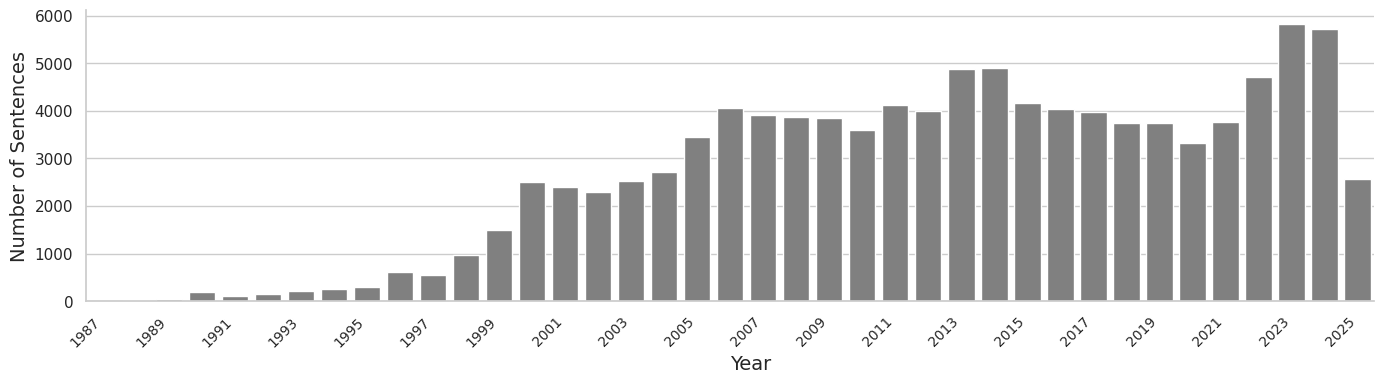

In [22]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys, csv
csv.field_size_limit(sys.maxsize)

# Paths
cleaned_path = (
    "/home/ec2-user/SageMaker/ADHD_conceptual_change/output/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned.csv"
)

summary_csv = "output/descriptives/ADHD_sentence_count_by_year.csv"
plot_png = "output/descriptives/ADHD_sentence_count_by_year.png"

# 1) Load cleaned sentences
df = pd.read_csv(cleaned_path, sep=",", engine="python")

# 2) Aggregate counts per year
year_counts = (
    df.groupby("year")
      .size()
      .reset_index(name="count")
)

# 3) Save the summary CSV
year_counts.to_csv(summary_csv, index=False)
print(f"✔ Saved sentence‐per‐year summary to: {summary_csv}")

# 4) Plot
year_counts["year_str"] = year_counts["year"].astype(str)
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 4))
sns.barplot(data=year_counts, x="year_str", y="count", color="grey")
plt.xlabel("Year", fontsize=14, ha="left")
plt.ylabel("Number of Sentences", fontsize=14)
plt.xticks(
    ticks=range(0, len(year_counts), 2),
    labels=year_counts["year_str"].iloc[::2],
    rotation=45, ha="right", fontsize=10
)
sns.despine()
plt.tight_layout()

# 5) Save the figure
plt.savefig(plot_png)
print(f"✔ Saved plot to: {plot_png}")

plt.show()

In [2]:
# ============================================================
# FINAL CORPUS DESCRIPTIVES — CLEANED ANALYTIC CORPUS
# Study period: 1990–2025
# ============================================================

import os
import pandas as pd
import sys, csv

csv.field_size_limit(sys.maxsize)

# ------------------------------------------------------------
# 1. Load FINAL cleaned sentence corpus
# ------------------------------------------------------------

cleaned_path = (
    "/home/ec2-user/SageMaker/"
    "ADHD_conceptual_change/output/"
    "ADHD_US_newsstream_normalized-ADHD_sentences_cleaned.csv"
)

df = pd.read_csv(cleaned_path, sep=",", engine="python")

# Make sure year is numeric
df["year"] = pd.to_numeric(df["year"], errors="coerce")

# IMPORTANT: restrict all final descriptives to the study period
df = df[df["year"].between(1990, 2025)].copy()

print("Study period:", int(df["year"].min()), "-", int(df["year"].max()))
print(f"Cleaned ADHD-containing sentences: {len(df):,}")


# ------------------------------------------------------------
# 2. Create article-level version of FINAL cleaned corpus
# ------------------------------------------------------------

# One row per unique article
article_df = df.drop_duplicates(subset="id").copy()

print(f"Unique articles represented: {article_df['id'].nunique():,}")
print(f"Unique publishers represented: {article_df['publisher'].nunique():,}")
print()


# ------------------------------------------------------------
# 3. Overall descriptive statistics
# ------------------------------------------------------------

stats = {
    # Sentence lengths
    "sentence_len_min": df["sentence_len"].min(),
    "sentence_len_med": df["sentence_len"].median(),
    "sentence_len_max": df["sentence_len"].max(),
    "sentence_len_mean": df["sentence_len"].mean(),
    "sentence_len_sd": df["sentence_len"].std(),

    # Article lengths
    "article_len_min": article_df["article_len"].min(),
    "article_len_med": article_df["article_len"].median(),
    "article_len_max": article_df["article_len"].max(),
    "article_len_mean": article_df["article_len"].mean(),
    "article_len_sd": article_df["article_len"].std(),

    # Sentence word lengths
    "sentence_word_len_min": df["sentence_word_len"].min(),
    "sentence_word_len_med": df["sentence_word_len"].median(),
    "sentence_word_len_max": df["sentence_word_len"].max(),
    "sentence_word_len_mean": df["sentence_word_len"].mean(),
    "sentence_word_len_sd": df["sentence_word_len"].std(),

    # Article word lengths
    "article_word_len_min": article_df["article_word_len"].min(),
    "article_word_len_med": article_df["article_word_len"].median(),
    "article_word_len_max": article_df["article_word_len"].max(),
    "article_word_len_mean": article_df["article_word_len"].mean(),
    "article_word_len_sd": article_df["article_word_len"].std(),

    # Corpus counts
    "n_sentences": len(df),
    "n_articles": article_df["id"].nunique(),
    "n_publishers": article_df["publisher"].nunique(),
}

stats_df = pd.DataFrame([stats])


# ------------------------------------------------------------
# 4. Corpus composition by year
# ------------------------------------------------------------

annual_summary = (
    df.groupby("year")
    .agg(
        n_sentences=("id", "size"),
        n_articles=("id", "nunique"),
        n_publishers=("publisher", lambda x: x.dropna().nunique())
    )
    .reset_index()
)

print("CORPUS COMPOSITION BY YEAR")
display(annual_summary)


# ------------------------------------------------------------
# 5. Overall source-type composition
# ------------------------------------------------------------

source_type_summary = (
    article_df["source_type"]
    .dropna()
    .value_counts()
    .rename_axis("source_type")
    .reset_index(name="n_articles")
)

source_type_summary["percent_articles"] = (
    source_type_summary["n_articles"]
    / len(article_df)
    * 100
)

source_type_summary["percent_articles"] = (
    source_type_summary["percent_articles"].round(2)
)

print("\nSOURCE TYPE COMPOSITION")
display(source_type_summary)


# ------------------------------------------------------------
# 6. Save descriptive files
# ------------------------------------------------------------

output_dir = "output/descriptives"
os.makedirs(output_dir, exist_ok=True)

stats_df.to_csv(
    os.path.join(output_dir, "final_cleaned_corpus_stats.csv"),
    index=False
)

annual_summary.to_csv(
    os.path.join(output_dir, "final_corpus_composition_by_year.csv"),
    index=False
)

source_type_summary.to_csv(
    os.path.join(output_dir, "final_source_type_summary.csv"),
    index=False
)

print("\nSaved:")
print(" - final_cleaned_corpus_stats.csv")
print(" - final_corpus_composition_by_year.csv")
print(" - final_source_type_summary.csv")

Study period: 1990 - 2025
Cleaned ADHD-containing sentences: 103,532
Unique articles represented: 45,236
Unique publishers represented: 191

CORPUS COMPOSITION BY YEAR


,year,n_sentences,n_articles,n_publishers
0,1990,185,47,11
1,1991,110,46,16
2,1992,143,61,13
3,1993,212,94,21
4,1994,247,149,25
5,1995,303,134,32
6,1996,610,244,34
7,1997,561,265,44
8,1998,977,369,46
9,1999,1496,605,43



SOURCE TYPE COMPOSITION


,source_type,n_articles,percent_articles
0,Newspapers,23522,52.00
1,Wire Feeds,18317,40.49
2,"Blogs, Podcasts, & Websites",3061,6.77
3,Trade Journals,186,0.41
4,Other Sources,91,0.20
5,Magazines,54,0.12
6,Reports,3,0.01
7,Audio & Video Works,2,0.00



Saved:
 - final_cleaned_corpus_stats.csv
 - final_corpus_composition_by_year.csv
 - final_source_type_summary.csv


# End of Script